# Statistical Analysis & Multi-Panel Galaxy Scaling Relations Dashboard

This notebook presents the complete statistical analysis of our **2,489-galaxy SDSS DR17 SQLite atlas** (`data/galaxy_atlas.db`), connecting SQL aggregations, power-law regressions, color-population separation, and correlation analysis into a publication-grade 6-panel dashboard.

## What We Analyze Here
1. **Morphology Distribution**: Pie & bar breakdown of early-type (`fracDeV_r >= 0.5`) vs. late-type (`fracDeV_r < 0.5`) galaxies.
2. **Stellar Mass–Size Relation ($R_{50}$ vs. $M_\star$)**: Quantitative power-law fits $\log_{10} R_{50} = \alpha (\log_{10} M_\star - 10.5) + \beta$ separately for early-type and late-type populations.
3. **Color–Magnitude Diagram ($g - r$ vs. $M_r$)**: Separating the passive **Red Sequence** from the star-forming **Blue Cloud** using the optical color cut $g - r = -0.025(M_r + 20) + 0.72$.
4. **Star Formation Rate Distributions**: Comparing $\log_{10}(\mathrm{SFR})$ histograms and quartiles across morphological types.
5. **Pearson Correlation Matrix**: Measuring linear correlations across all 9 physical and photometric parameters.

In [1]:
import json
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.analysis import (
    classify_color_population,
    compute_correlation_matrix,
    fit_mass_size_power_law,
    load_morphology_summary,
    load_scaling_relations_sample,
    plot_statistical_dashboard,
)
from src.config import ProjectConfig
from src.database import GalaxyDatabase

config = ProjectConfig()
with GalaxyDatabase(config.db_path) as db:
    summary_df = load_morphology_summary(db)
    sample_df = load_scaling_relations_sample(db)

print(f"Loaded {len(sample_df):,} clean SDSS DR17 galaxies from {config.db_path}")
display(summary_df)

Loaded 2,489 clean SDSS DR17 galaxies from C:\Things\Astrophysics_Antigravity_Pj\AstrophysicsProjectRepo\data\galaxy_atlas.db


,morph_proxy,galaxy_count,avg_log_stellar_mass,avg_re_kpc,avg_color_gr,avg_log_sfr,avg_concentration
0,early,1368,10.590385,3.184679,0.884450,-0.894362,2.857193
1,late,1121,10.031703,3.856701,0.649922,-0.095272,2.250398


---
## Step 1: Quantitative Power-Law Mass–Size Fits & Red Sequence / Blue Cloud Separation

In extragalactic astrophysics (e.g., Shen et al. 2003; van der Wel et al. 2014), early-type spheroids follow a **steeper** mass–size power-law slope ($\alpha_{\text{early}} > \alpha_{\text{late}}$) and are more compact at fixed stellar mass ($M_\star = 10^{10.5} M_\odot$) than late-type rotating disks. Let's fit both populations directly from our SQLite catalog.

In [2]:
fits = fit_mass_size_power_law(sample_df)
print("=== Stellar Mass-Size Power-Law Fits ===")
print(json.dumps(fits, indent=2))

annotated_df = classify_color_population(sample_df)
crosstab = pd.crosstab(annotated_df["morph_proxy"], annotated_df["color_population"], margins=True)
print("\n=== Red Sequence vs. Blue Cloud Crosstab ===")
display(crosstab)

=== Stellar Mass-Size Power-Law Fits ===
{
  "early": {
    "n": 1368,
    "alpha_slope": 0.310728023755794,
    "beta_intercept_at_10p5": 0.43173840716474404,
    "re_kpc_at_10p5": 2.702330152886339,
    "r_squared": 0.4956890223680764,
    "p_value": 2.6867686927960364e-205,
    "stderr": 0.008480073835065213
  },
  "late": {
    "n": 1121,
    "alpha_slope": 0.18499382700011927,
    "beta_intercept_at_10p5": 0.6396446777322546,
    "re_kpc_at_10p5": 4.361588386117929,
    "r_squared": 0.30152905189043366,
    "p_value": 2.7407580428604828e-89,
    "stderr": 0.008416892607231002
  }
}

=== Red Sequence vs. Blue Cloud Crosstab ===


color_population,blue_cloud,red_sequence,All
morph_proxy,,,
early,159,1209,1368
late,781,340,1121
All,940,1549,2489


---
## Step 2: Pearson Correlation Matrix

Computing pairwise Pearson correlations reveals the dominant physical couplings in local galaxies:
- **Luminosity–Mass Coupling**: $M_r$ correlates strongly negatively with $\log_{10} M_\star$ (brighter = more negative $M_r$ = higher stellar mass).
- **Structure–Color–Quenching Coupling**: Higher light concentration $C = R_{90}/R_{50}$ and `fracDeV_r` correlate positively with redder $g - r$ color and negatively with $\log_{10}\mathrm{SFR}$.

In [3]:
corr_df = compute_correlation_matrix(sample_df)
display(corr_df.round(3))

,redshift,abs_mag_r,color_gr,color_ug,log_stellar_mass,log_sfr,re_kpc,concentration,frac_dev_r
redshift,1.000,-0.615,0.294,0.218,0.567,0.079,0.336,0.127,0.231
abs_mag_r,-0.615,1.000,-0.401,-0.389,-0.906,-0.044,-0.550,-0.345,-0.419
color_gr,0.294,-0.401,1.000,0.488,0.623,-0.412,0.018,0.472,0.497
color_ug,0.218,-0.389,0.488,1.000,0.611,-0.610,-0.040,0.548,0.586
log_stellar_mass,0.567,-0.906,0.623,0.611,1.000,-0.143,0.382,0.492,0.538
log_sfr,0.079,-0.044,-0.412,-0.610,-0.143,1.000,0.379,-0.502,-0.581
re_kpc,0.336,-0.550,0.018,-0.040,0.382,0.379,1.000,-0.240,-0.221
concentration,0.127,-0.345,0.472,0.548,0.492,-0.502,-0.240,1.000,0.819
frac_dev_r,0.231,-0.419,0.497,0.586,0.538,-0.581,-0.221,0.819,1.000


---
## Step 3: Render & Export the 6-Panel Publication Dashboard

The cell below generates the complete 6-panel dashboard and saves both PNG (`outputs/figures/statistical_dashboard.png`) and vector PDF (`outputs/figures/statistical_dashboard.pdf`).

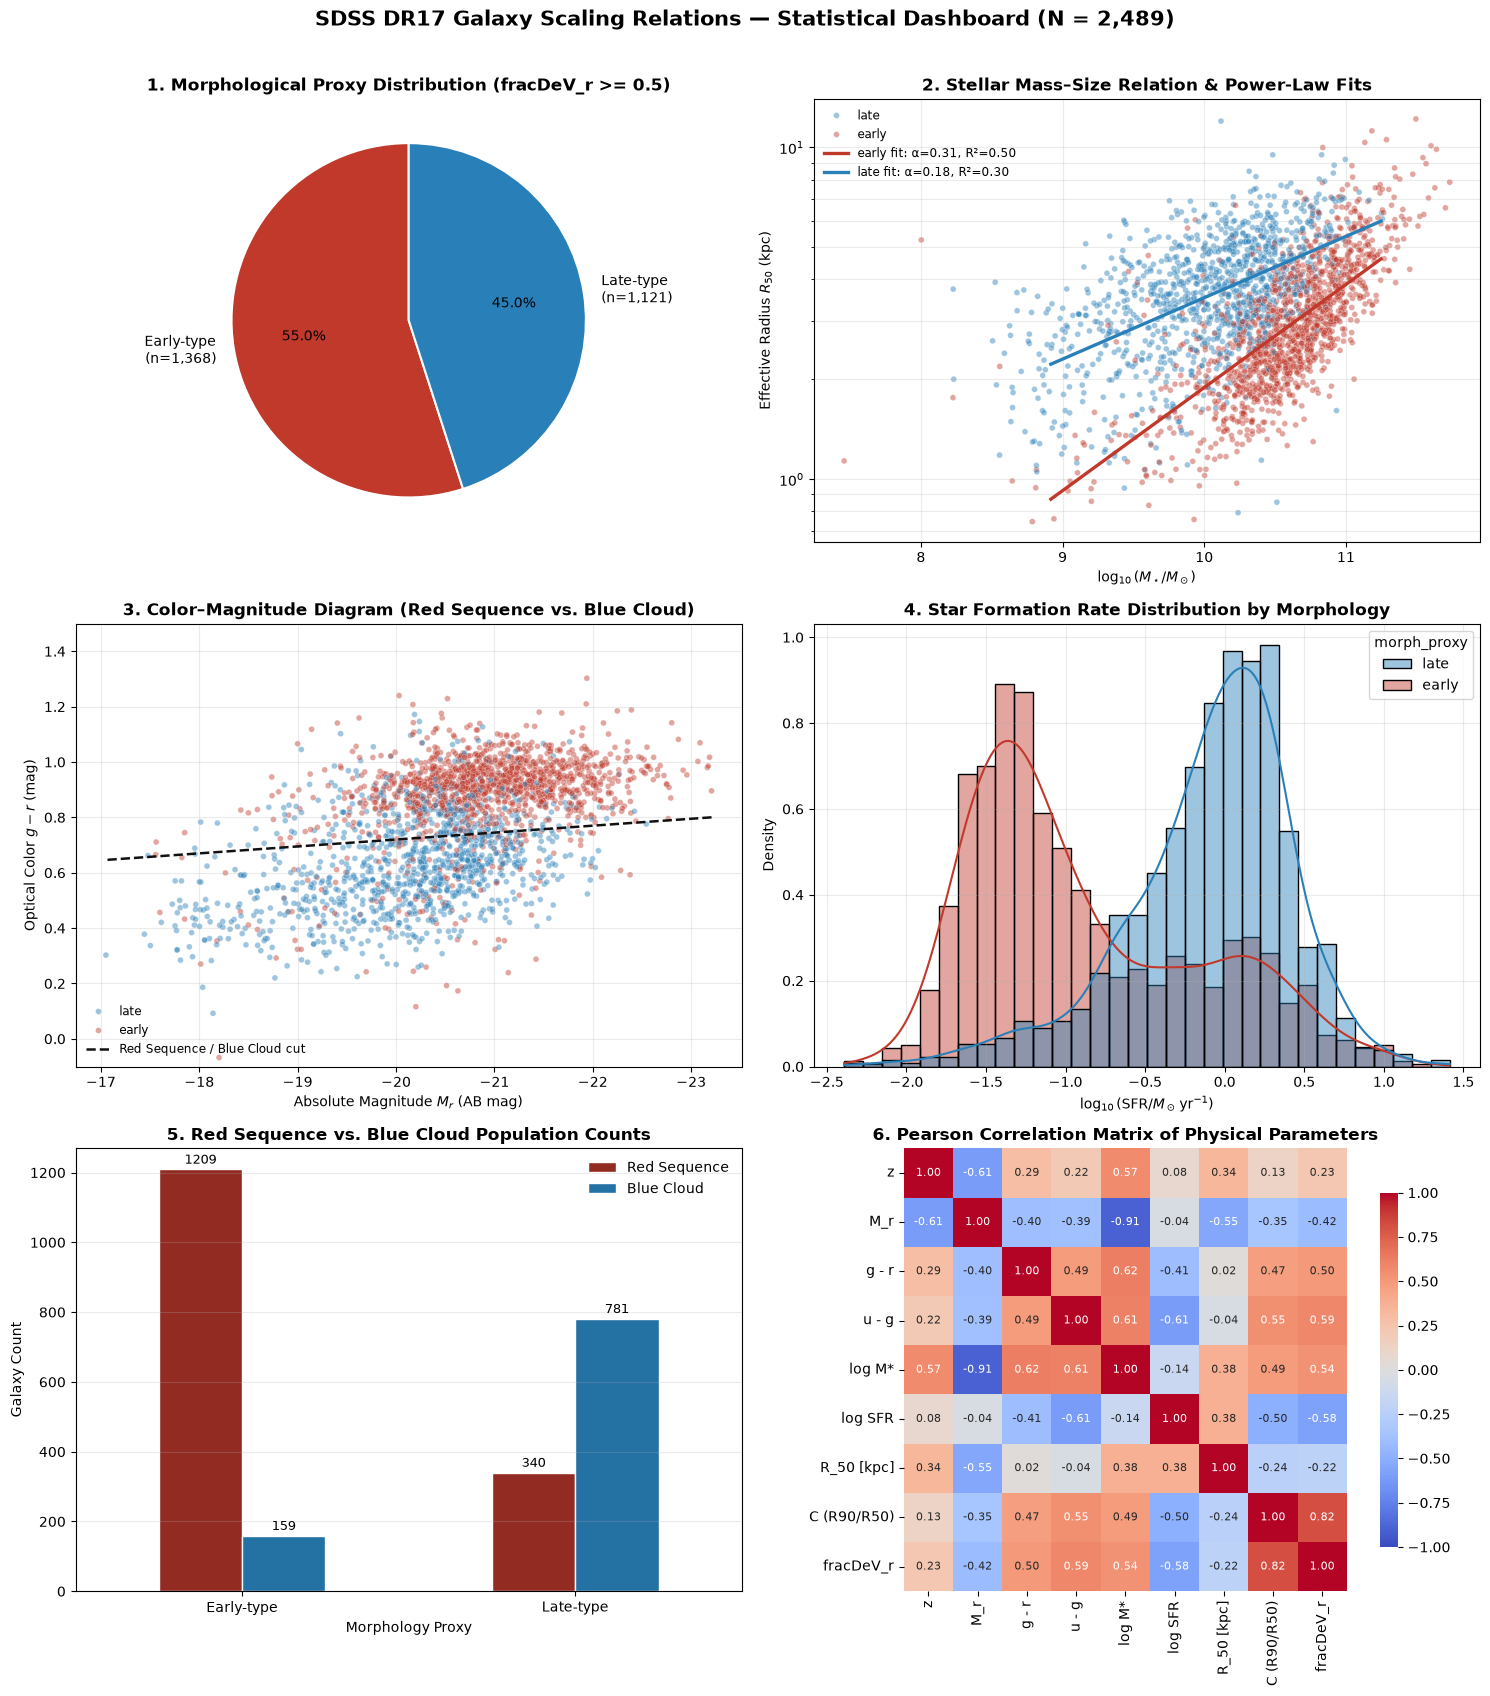

Saved PNG & PDF dashboards to: C:\Things\Astrophysics_Antigravity_Pj\AstrophysicsProjectRepo\outputs\figures


In [4]:
config.ensure_directories()
fig, dash_metrics = plot_statistical_dashboard(
    sample_df,
    output_png=config.figures_dir / "statistical_dashboard.png",
    output_pdf=config.figures_dir / "statistical_dashboard.pdf",
)
plt.show()
print("Saved PNG & PDF dashboards to:", config.figures_dir)